# Étape 2 — Modèle de prédiction du rendement, optimisation et suivi MLflow

**Projet :** système de recommandation de cultures — Agritech Answers

**Objectif :** construire le cœur de l'application : un modèle qui **prédit le rendement (t/ha)** d'une culture à partir des conditions de la parcelle. Plusieurs modèles sont entraînés sur le dataset consolidé de l'étape 1, comparés sur des métriques **statistiques** (RMSE, MAE, R²) et **économiques** (erreur sur la marge, rentabilité), puis le meilleur est optimisé. Chaque expérimentation est tracée dans **MLflow**. Le modèle est enfin traduit en **recommandations pour l'agriculteur**.

**Plan**
1. Données et découpage entraînement / test
2. Métriques d'évaluation et hypothèses économiques
3. Pipeline de préparation
4. Comparaison des modèles
5. Sélection des variables
6. Optimisation des hyperparamètres
7. Modèle final : évaluation sur le jeu de test
8. Interprétation : quelles variables comptent ?
9. Recommandations pour l'agriculteur
10. Sauvegarde et traçabilité MLflow
11. Synthèse

Le pipeline est codé dans `src/entrainement.py` (exécutable seul : `python -m src.entrainement`) et les hypothèses économiques dans `src/economie.py`. Ce notebook l'exécute pas à pas, l'explique et en interprète les résultats.

**Ouvrir l'interface MLflow** (depuis la racine du projet) : `mlflow ui --backend-store-uri sqlite:///mlflow.db`, puis http://127.0.0.1:5000.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import ListedColormap
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import economie
from src import entrainement as ent

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)
TARGET = ent.TARGET
CROPS = ent.CROPS
CROP_COLORS = dict(zip(CROPS, sns.color_palette("deep", len(CROPS))))

ent.setup_mlflow()
print("Suivi MLflow :", ent.TRACKING_URI)
print(f"Expérience : {ent.EXPERIMENT} | graine aléatoire : {ent.SEED}")

2026/11/11 14:14:59 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/11 14:14:59 INFO mlflow.store.db.utils: Updating database tables


Suivi MLflow : sqlite:///C:/Users/j-a-b/Documents/OpenClassrooms/Projet 11 système de recommandations pour une agriculture optimisée par les données/mlflow.db
Expérience : P11_rendement_cultures | graine aléatoire : 42


## 1. Données et découpage entraînement / test

Le **jeu de test (20 %)** est mis de côté avant toute modélisation. Il ne sert qu'une seule fois, à la fin, pour mesurer la performance sur des parcelles jamais vues : c'est la garantie contre le **surapprentissage**.

**Découpage par donneur.** Chaque parcelle a hérité son rendement d'un donneur FAO (un pays une année donnée, cf. étape 1), et plusieurs dizaines de parcelles partagent le même donneur. Or la valeur exacte de `Pesticides_tonnes` est un total national propre à chaque pays-année : avec la culture, elle désigne presque le donneur. Un découpage purement aléatoire placerait des parcelles d'un même donneur des deux côtés, et le modèle pourrait « reconnaître » le donneur au lieu d'apprendre l'effet des conditions. Un essai préalable l'a confirmé : R² ≈ 0,91 en découpage aléatoire contre ≈ 0,78 en découpage par donneur. On sépare donc **par donneur** (approché par culture × valeur des pesticides) : le test mesure la performance sur des **pays-années jamais vus**, ce qui correspond à la situation réelle d'un nouvel agriculteur.

Pour comparer et optimiser les modèles, on utilise la **validation croisée à 3 plis**, elle aussi par donneur, sur un échantillon de 150 000 parcelles du jeu d'entraînement : chaque modèle est entraîné 3 fois sur 2/3 de l'échantillon et évalué sur le tiers restant. L'échantillon limite le temps de calcul (une vingtaine de configurations à tester) tout en restant très large. La graine aléatoire est fixée (`SEED = 42`) : découpage, échantillons et modèles sont **reproductibles**.

In [2]:
df = ent.load_data()
train, test = ent.split(df)
print(f"Dataset consolidé : {len(df):,} parcelles | entraînement : {len(train):,} | test : {len(test):,}")
pd.DataFrame({
    "entraînement (%)": train["Crop"].value_counts(normalize=True) * 100,
    "test (%)": test["Crop"].value_counts(normalize=True) * 100,
}).round(2)

Dataset consolidé : 666,494 parcelles | entraînement : 536,841 | test : 129,653


,entraînement (%),test (%)
Crop,,
Maize,24.430,27.470
Rice,25.180,24.350
Soybean,25.300,23.520
Wheat,25.080,24.660


## 2. Métriques d'évaluation et hypothèses économiques

| Métrique | Lecture | Objectif |
|---|---|---|
| **RMSE** (t/ha) | erreur type de prédiction, pénalise fortement les grosses erreurs | le plus bas possible |
| **MAE** (t/ha) | erreur moyenne en valeur absolue : « en moyenne, on se trompe de X t/ha » | le plus bas possible |
| **R²** | part des variations de rendement expliquée par le modèle (0 = rien, 1 = tout) | le plus proche de 1 |
| **RMSE marge** (USD/ha) | erreur sur la marge de l'agriculteur : une tonne de soja mal prédite coûte plus qu'une tonne de maïs | le plus bas possible |
| **Précision rentabilité** | part des parcelles correctement classées rentables / non rentables | le plus proche de 100 % |

Les deux dernières traduisent l'objectif métier de Gabriel : *maximiser les profits*. Aucun des jeux de données ne contient de prix ni de coûts. Les valeurs ci-dessous (`src/economie.py`) viennent de sources publiques :
- **prix** : Banque mondiale (*Pink Sheet*), moyenne 2025 des cours mondiaux ; le riz est converti en équivalent paddy (taux d'usinage FAO 0,67) ;
- **coûts** : USDA ERS (*Commodity Costs and Returns*), coûts opérationnels 2025 hors terre et matériel, ramenés à l'intensité des parcelles du jeu de données (rendements américains 1,3 à 3,4 fois plus élevés) ;
- **irrigation** : 200 USD/ha, ordre de grandeur **illustratif**, faute de source comparable.

Ce sont des références, à remplacer par les prix et coûts réels du client. Le modèle prédit le rendement : changer ces hypothèses ne demande pas de le réentraîner.

> **marge (USD/ha) = rendement × prix − coût de base − coût de l'engrais de la culture (si utilisé) − coût de l'irrigation (si utilisée)**

In [3]:
hyp = pd.DataFrame({"prix (USD/t)": economie.PRIX_USD_T, "coût de base (USD/ha)": economie.COUT_BASE_USD_HA,
                    "coût engrais (USD/ha)": economie.COUT_ENGRAIS_USD_HA})
for fert, irr, label in [(0, 0, "sans intrants"), (1, 0, "engrais"), (0, 1, "irrigation"), (1, 1, "engrais + irrigation")]:
    hyp[f"seuil rentabilité {label} (t/ha)"] = [economie.seuil_rentabilite(c, fert, irr) for c in hyp.index]
print(f"Coût irrigation (illustratif) : {economie.COUT_IRRIGATION_USD_HA:.0f} USD/ha")
hyp

Coût irrigation (illustratif) : 200 USD/ha


,prix (USD/t),coût de base (USD/ha),coût engrais (USD/ha),seuil rentabilité sans intrants (t/ha),seuil rentabilité engrais (t/ha),seuil rentabilité irrigation (t/ha),seuil rentabilité engrais + irrigation (t/ha)
Maize,203.200,205.600,124.600,1.012,1.625,1.996,2.609
Rice,273.200,594.700,194.800,2.177,2.890,2.909,3.622
Soybean,414.000,196.000,60.600,0.473,0.620,0.957,1.103
Wheat,243.300,188.300,121.600,0.774,1.274,1.596,2.096


Le **seuil de rentabilité** est le rendement minimal pour couvrir les coûts. Le soja, le mieux valorisé à la tonne, est rentable dès ~0,5 t/ha sans intrants ; le riz, le plus coûteux à produire, demande plus de 2 t/ha.

## 3. Pipeline de préparation

La préparation et le modèle forment **un seul objet scikit-learn** (`Pipeline`) :
- **Catégorielles** (culture, région, sol, météo) → encodage *one-hot* (une colonne 0/1 par modalité) ;
- **Pesticides** → `log(1 + x)` puis standardisation : la variable s'étale sur 7 ordres de grandeur (cf. étape 1) ;
- **Numériques** (pluie, température, durée) → standardisation (moyenne 0, écart-type 1) ;
- **Engrais, irrigation** → déjà en 0/1, conservés tels quels.

Les paramètres de préparation (moyennes, écarts-types, modalités) sont appris **uniquement sur les données d'entraînement de chaque pli** : aucune information du jeu de validation ou de test ne fuit dans l'entraînement. Autre avantage : le modèle enregistré accepte directement les données brutes saisies par l'agriculteur dans l'application.

In [4]:
ent.build_pipeline(ent.candidate_models()["Gradient boosting (HGB)"], ent.FEATURES_ALL)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('log', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__

## 4. Comparaison des modèles

| Modèle | Principe | Pourquoi le tester |
|---|---|---|
| **Baseline** | prédit toujours le rendement moyen | point de référence : tout modèle utile doit faire mieux |
| **Régression Ridge** | somme pondérée des variables (linéaire, régularisée) | simple et interprétable ; teste si des relations linéaires suffisent |
| **Forêt aléatoire** | moyenne de 100 arbres de décision (feuilles d'au moins 20 parcelles) | capte les non-linéarités et interactions (culture × climat) |
| **Gradient boosting (HGB)** | arbres construits successivement, chacun corrigeant les erreurs du précédent | souvent le plus performant sur données tabulaires, rapide sur gros volumes |

**Contrainte de déploiement :** le modèle sera chargé en mémoire par l'API. Une forêt aux feuilles d'une seule parcelle pèserait environ 5 Go (mesuré) ; on impose donc des feuilles d'au moins 20 parcelles (~100 Mo), et la taille du modèle final est journalisée dans MLflow.

Chaque modèle est un **run MLflow** (paramètres, métriques de validation croisée et note explicative), regroupé sous le run parent `A_comparaison_modeles`. Le meilleur est ensuite réévalué avec les seules **6 variables clés** identifiées à l'étape 1.

In [5]:
table = ent.compare_models(train)
cols = ["cv_rmse", "cv_rmse_std", "cv_mae", "cv_r2", "cv_rmse_marge_usd_ha", "cv_precision_rentabilite", "duree_cv_s"]
table[cols].astype(float)

,cv_rmse,cv_rmse_std,cv_mae,cv_r2,cv_rmse_marge_usd_ha,cv_precision_rentabilite,duree_cv_s
Foret aleatoire - variables cles,1.236,0.077,0.777,0.742,305.130,0.840,16.561
Foret aleatoire,1.238,0.075,0.778,0.741,305.495,0.840,24.191
Gradient boosting (HGB),1.245,0.046,0.826,0.738,307.544,0.810,12.249
Regression Ridge,1.940,0.072,1.393,0.364,481.536,0.701,8.798
Baseline (moyenne),2.434,0.095,1.792,-0.000,630.335,0.689,9.095


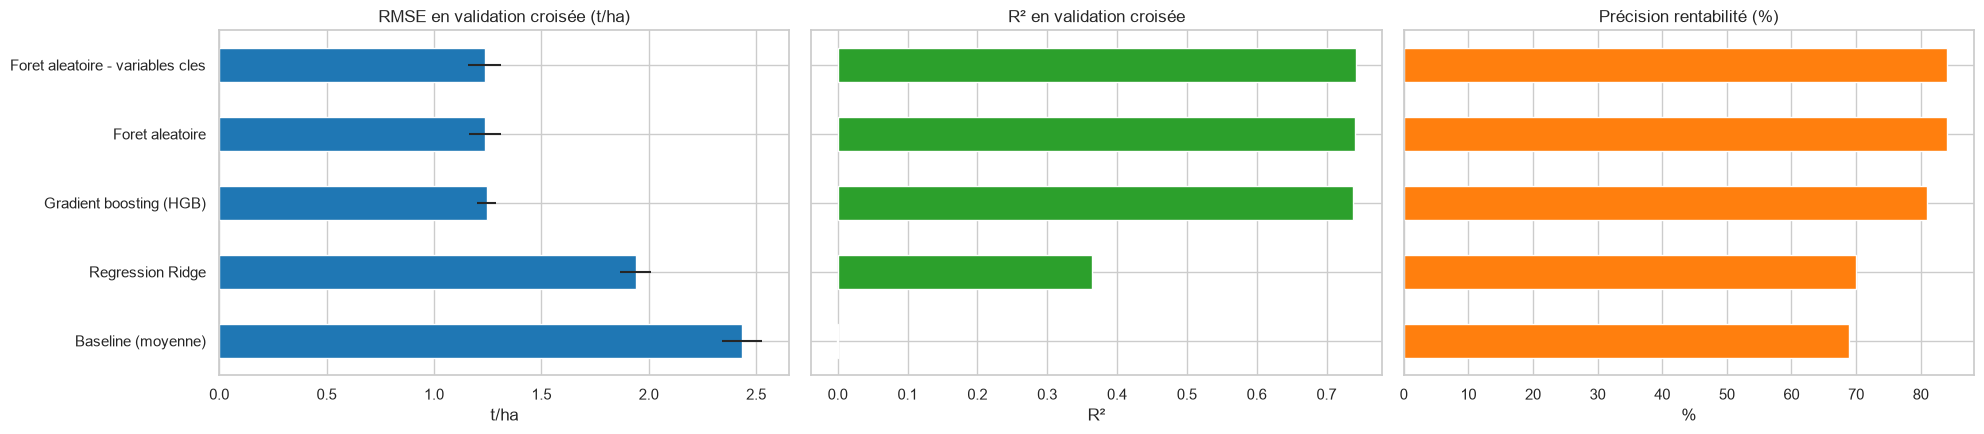

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
t = table[cols].astype(float).iloc[::-1]
t["cv_rmse"].plot.barh(ax=axes[0], xerr=t["cv_rmse_std"], color="tab:blue").set(title="RMSE en validation croisée (t/ha)", xlabel="t/ha")
t["cv_r2"].plot.barh(ax=axes[1], color="tab:green").set(title="R² en validation croisée", xlabel="R²")
(t["cv_precision_rentabilite"] * 100).plot.barh(ax=axes[2], color="tab:orange").set(title="Précision rentabilité (%)", xlabel="%")
for ax in axes[1:]:
    ax.set_yticklabels([])
plt.tight_layout()
plt.show()

**Constats :**
- La **baseline** (R² = 0) et la **régression Ridge** (R² ≈ 0,36) sont nettement distancées. Un modèle linéaire ne peut pas représenter le fait central de l'étape 1 : **l'effet du climat dépend de la culture** (le maïs aime la fraîcheur, le riz la chaleur). Il faut des modèles capables de capter ces interactions.
- **Forêt aléatoire et gradient boosting sont au coude-à-coude** : RMSE ≈ 1,24 t/ha et R² ≈ 0,74 pour les deux. L'écart entre eux (≈ 0,01 t/ha) est inférieur à la variabilité d'un pli à l'autre (écart-type 0,05 à 0,08). La forêt l'emporte légèrement sur les métriques métier : erreur moyenne plus faible (MAE 0,78 contre 0,83 t/ha) et **rentabilité mieux classée (84 % contre 81 %)**. C'est la famille retenue pour l'optimisation.
- Les modèles expliquent environ **74 % des variations de rendement** sur des pays-années jamais vus. La part restante est en grande partie irréductible : à l'étape 1, chaque parcelle a reçu le rendement d'un donneur **tiré au hasard** parmi les 10 plus proches, ce qui introduit une variabilité qu'aucune variable ne peut expliquer.

## 5. Sélection des variables

Règle de décision (fixée avant de voir les résultats, `PARSIMONY_TOLERANCE`) : on retient le **jeu réduit à 6 variables** si sa RMSE ne dépasse pas celle du jeu complet de plus de **1 %**. Un modèle plus simple est plus robuste, plus facile à expliquer, et l'agriculteur n'a que 6 champs à remplir dans l'application au lieu de 10.

In [7]:
features = ent.choose_features(table)
estimator = ent.best_family(table)
print("Famille de modèle retenue :", type(estimator).__name__)
print("Variables retenues        :", features)

Famille de modèle retenue : RandomForestRegressor
Variables retenues        : ['Crop', 'Rainfall_mm', 'Temperature_Celsius', 'Pesticides_tonnes', 'Fertilizer_Used', 'Irrigation_Used']


**Constats :** avec les 6 variables clés, la forêt obtient une RMSE de **1,236 t/ha contre 1,238** avec les 10 variables. Retirer la région, le type de sol, la météo dominante et la durée de culture **ne dégrade rien** (c'est même très légèrement meilleur, car le modèle n'est plus distrait par des variables sans signal). Cela confirme le constat de l'étape 1 : ces 4 variables n'ont aucun effet sur le rendement. **Le jeu réduit est retenu** : culture, pluie, température, pesticides, engrais, irrigation.

## 6. Optimisation des hyperparamètres

Les **hyperparamètres** règlent la façon dont le modèle apprend (vitesse d'apprentissage, taille et nombre des arbres, régularisation). Ils ne sont pas appris à partir des données : on les choisit en testant plusieurs configurations.

Méthode : **recherche aléatoire** de 20 configurations (plus efficace qu'une grille exhaustive à budget égal), chacune évaluée en validation croisée à 3 plis. Chaque configuration est un run MLflow enfant (`essai_01` à `essai_20`) du run parent `B_optimisation_…`, ce qui permet de les comparer dans l'interface (vue tableau, graphiques de coordonnées parallèles).

In [8]:
pd.Series({k.removeprefix("model__"): (f"loguniforme({v.a}, {v.b})" if hasattr(v, "a") else v)
           for k, v in ent.TUNING_SPACES[type(estimator).__name__].items()}, name="valeurs testées").to_frame()

,valeurs testées
max_depth,"[None, 12, 20]"
min_samples_leaf,"[20, 50, 100]"
max_features,"[0.3, 0.6, 1.0]"
max_samples,"[0.3, 0.5]"


In [9]:
best_params, trials = ent.tune(train, estimator, features)
show = [c for c in trials.columns if c.startswith("model__")] + ["cv_rmse", "cv_r2", "cv_precision_rentabilite", "duree_cv_s"]
print("Meilleure configuration :", {k.removeprefix("model__"): v for k, v in best_params.items()})
trials[show].rename(columns=lambda c: c.removeprefix("model__")).head(8)

Meilleure configuration : {'min_samples_leaf': 20, 'max_samples': 0.5, 'max_features': 0.6, 'max_depth': 20}


,min_samples_leaf,max_samples,max_features,max_depth,cv_rmse,cv_r2,cv_precision_rentabilite,duree_cv_s
0,20,0.500,0.600,20.000,1.225,0.747,0.840,14.846
1,20,0.500,0.300,NaN,1.254,0.735,0.823,12.292
2,20,0.300,0.600,NaN,1.260,0.732,0.832,12.756
3,20,0.300,1.000,NaN,1.265,0.730,0.837,14.319
4,20,0.300,1.000,20.000,1.265,0.730,0.837,15.331
5,20,0.500,1.000,12.000,1.267,0.729,0.833,16.538
6,20,0.300,0.600,12.000,1.280,0.724,0.825,12.606
7,50,0.500,1.000,20.000,1.330,0.701,0.826,15.887


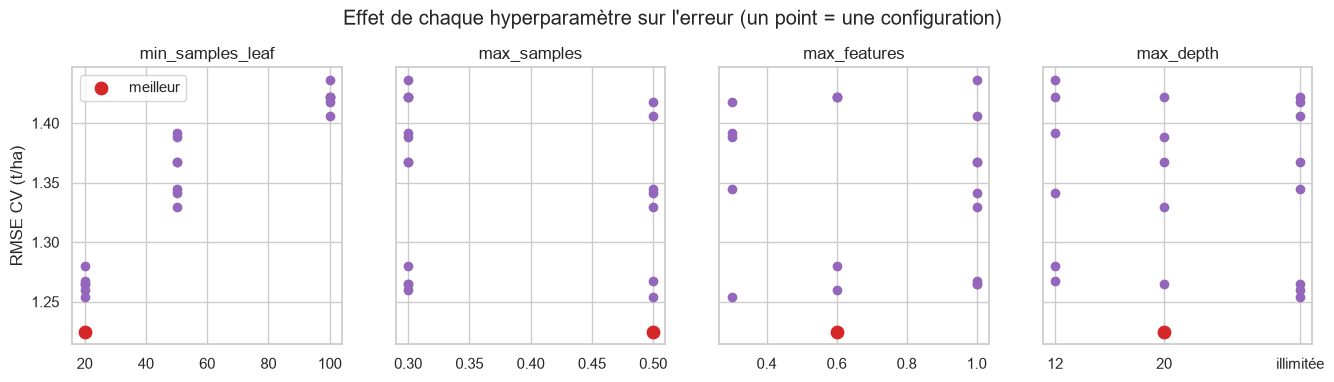

In [10]:
params = [c for c in trials.columns if c.startswith("model__")]
fig, axes = plt.subplots(1, len(params), figsize=(4 * len(params), 3.6), sharey=True)
for ax, p in zip(axes, params):
    # Profondeur illimitée (None) placée à droite des valeurs testées
    x = trials[p].astype(float)
    unlimited = x.isna()
    x = x.fillna(x.max() * 1.5 if x.notna().any() else 1)
    ax.scatter(x, trials["cv_rmse"], color="tab:purple")
    ax.scatter(x.iloc[:1], trials["cv_rmse"].iloc[:1], color="tab:red", s=80, label="meilleur")
    ax.set_title(p.removeprefix("model__"))
    if unlimited.any():
        ticks = sorted(x.unique())
        ax.set_xticks(ticks, [("illimitée" if t == x[unlimited].iloc[0] else f"{t:g}") for t in ticks])
    if p in ("model__learning_rate", "model__l2_regularization"):
        ax.set_xscale("log")
axes[0].set_ylabel("RMSE CV (t/ha)")
axes[0].legend()
plt.suptitle("Effet de chaque hyperparamètre sur l'erreur (un point = une configuration)", y=1.04)
plt.show()

**Constats :**
- **Meilleure configuration :** feuilles d'au moins 20 parcelles, chaque arbre entraîné sur 50 % des parcelles et 60 % des variables à chaque nœud, profondeur limitée à 20. RMSE CV **1,225 t/ha** (R² 0,747), contre 1,236 avec les réglages par défaut : un **gain modeste (≈ 1 %)**, les réglages initiaux étant déjà raisonnables.
- **L'hyperparamètre décisif est la taille minimale des feuilles** : 20 parcelles → RMSE 1,22 à 1,28 ; 50 → 1,33 à 1,39 ; 100 → plus de 1,40. Des feuilles plus petites suivent mieux les spécificités de chaque climat. On s'arrête à 20 pour respecter la contrainte de taille du modèle.
- Les autres réglages (profondeur, part des variables et des parcelles) n'ont qu'un effet de second ordre, de quelques centièmes de t/ha.

## 7. Modèle final : évaluation sur le jeu de test

Le modèle optimisé est réentraîné sur **l'ensemble du jeu d'entraînement**, puis évalué **une seule fois** sur le jeu de test. On compare aussi l'erreur sur les données d'entraînement et de test : un écart important signalerait un surapprentissage (modèle qui « récite » au lieu de généraliser). Le modèle est enregistré dans le registre MLflow sous le nom `rendement_cultures`.

In [11]:
model, metrics, importance, figs, run_id = ent.train_final(train, test, estimator, best_params, features)
names = ["rmse", "mae", "r2", "rmse_marge_usd_ha", "precision_rentabilite"]
print(f"Taille du modèle en mémoire : {metrics['taille_modele_mo']:.0f} Mo")
pd.DataFrame({"entraînement": [metrics[f"train_{n}"] for n in names],
              "test": [metrics[f"test_{n}"] for n in names]}, index=names)

C:\Users\j-a-b\Documents\OpenClassrooms\Projet 11 système de recommandations pour une agriculture optimisée par les données\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Taille du modèle en mémoire : 109 Mo


Successfully registered model 'rendement_cultures'.
Created version '1' of model 'rendement_cultures'.


,entraînement,test
rmse,0.681,1.177
mae,0.420,0.684
r2,0.921,0.760
rmse_marge_usd_ha,169.266,274.734
precision_rentabilite,0.921,0.843


In [12]:
pred = model.predict(test[features])
per_crop = []
for crop in CROPS:
    m = (test["Crop"] == crop).to_numpy()
    per_crop.append({"Culture": crop, "rendement moyen réel": test.loc[m, TARGET].mean(),
                     **ent.evaluate(test[m], test.loc[m, TARGET], pred[m])})
per_crop = pd.DataFrame(per_crop).set_index("Culture")
per_crop["erreur relative (MAE / moyenne)"] = per_crop["mae"] / per_crop["rendement moyen réel"]
per_crop

,rendement moyen réel,rmse,mae,r2,rmse_marge_usd_ha,precision_rentabilite,erreur relative (MAE / moyenne)
Culture,,,,,,,
Maize,3.672,1.795,1.045,0.715,364.798,0.800,0.285
Rice,3.402,0.928,0.660,0.761,253.630,0.822,0.194
Soybean,1.579,0.481,0.350,0.717,198.998,0.863,0.222
Wheat,2.655,0.977,0.624,0.753,237.796,0.891,0.235


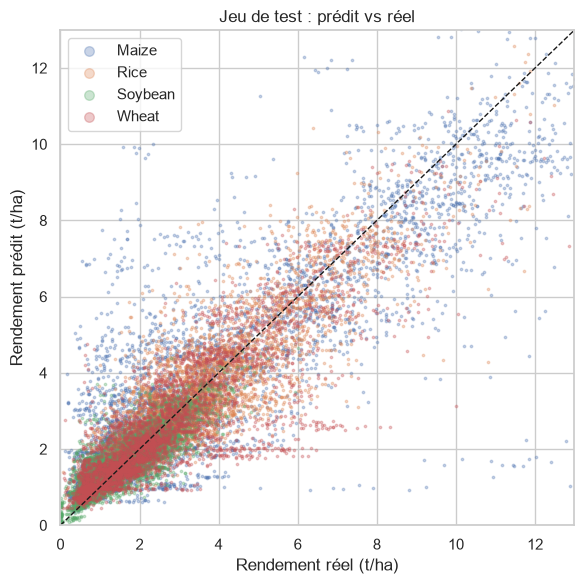

In [13]:
display(figs["predit_vs_reel.png"])

**Constats :**
- **Sur le jeu de test** (pays-années jamais vus) : RMSE **1,18 t/ha**, erreur moyenne **0,68 t/ha**, **R² = 0,76**. Le modèle classe correctement la parcelle comme rentable ou non rentable dans **84 % des cas** (avec les hypothèses économiques sourcées). Ces résultats sont cohérents avec la validation croisée (R² 0,75) : l'estimation de performance est fiable.
- **Écart entraînement / test** : R² 0,92 sur les données d'entraînement contre 0,76 en test. La forêt retient en partie les rendements propres aux pays-années qu'elle a vus. Ce n'est pas un défaut caché : le découpage par donneur mesure précisément la performance sur des situations nouvelles, et c'est le chiffre de test qu'il faut retenir pour l'agriculteur.
- **Par culture** : le **riz** est le mieux prédit (erreur relative 19 %), le **maïs** le moins bien (28 %). Le maïs a la plus large plage de rendements : jusqu'à plus de 10 t/ha en climat frais, d'où des erreurs absolues plus grandes. Sur le graphique, les points se regroupent autour de la diagonale ; les rendements très élevés (> 8 t/ha) sont légèrement sous-estimés, comportement classique d'une moyenne d'arbres.

## 8. Interprétation : quelles variables comptent ?

### 8.1 Importance par permutation

Méthode : on **brouille** les valeurs d'une variable (on les mélange entre parcelles) et on mesure de combien l'erreur du modèle augmente. Plus l'erreur augmente, plus le modèle s'appuie sur cette variable. La mesure est faite sur 20 000 parcelles du jeu de test.

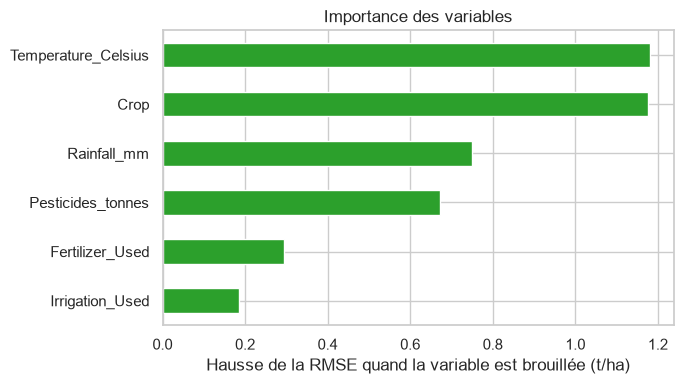

,hausse de RMSE (t/ha)
Temperature_Celsius,1.180
Crop,1.177
Rainfall_mm,0.750
Pesticides_tonnes,0.671
Fertilizer_Used,0.293
Irrigation_Used,0.186


In [14]:
display(figs["importance_variables.png"])
importance.to_frame("hausse de RMSE (t/ha)")

### 8.2 Effet de chaque variable sur le rendement prédit

Pour chaque culture, on fait varier une seule variable sur des parcelles réelles du jeu de test, toutes les autres restant inchangées, et on trace le rendement moyen prédit (*dépendance partielle*). Cela montre **dans quel sens** et **avec quelle ampleur** chaque condition modifie le rendement.

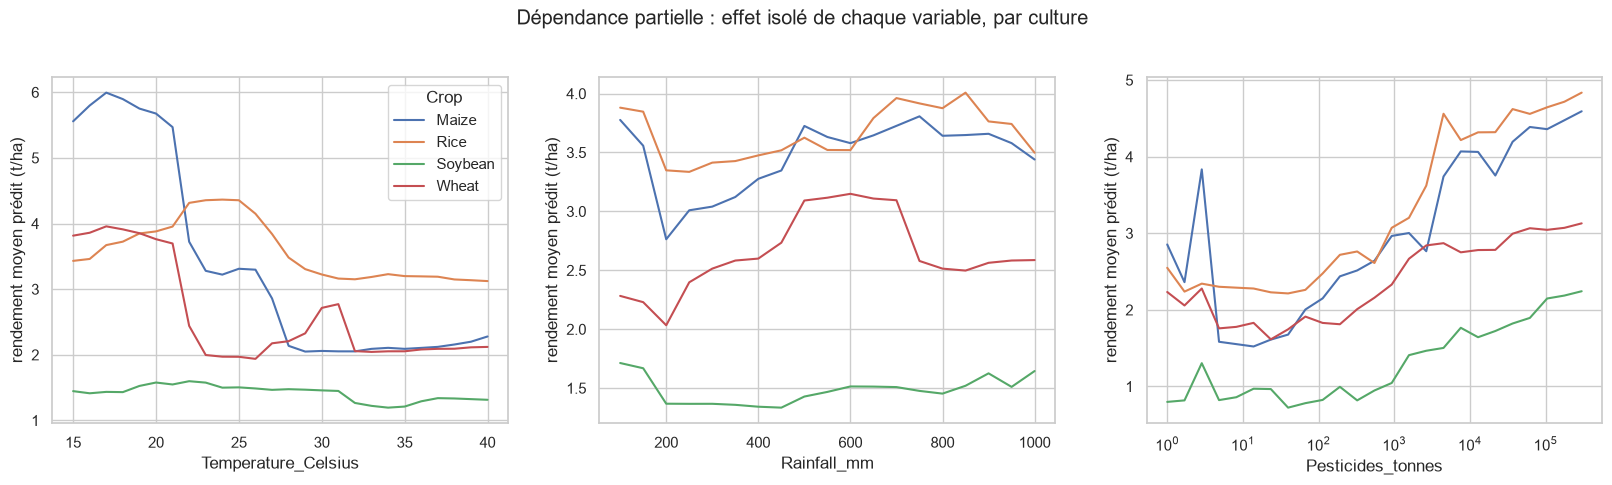

In [15]:
sample = test.sample(4_000, random_state=ent.SEED)

def partial_dependence(col, values):
    rows = []
    for crop in CROPS:
        base = sample[features].assign(Crop=crop)
        for v in values:
            rows.append({"Crop": crop, col: v, "rendement": model.predict(base.assign(**{col: v})).mean()})
    return pd.DataFrame(rows)

grids = {
    "Temperature_Celsius": np.linspace(15, 40, 26),
    "Rainfall_mm": np.linspace(100, 1000, 19),
    "Pesticides_tonnes": np.geomspace(1, 300_000, 25),
}
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
for ax, (col, values) in zip(axes, grids.items()):
    pdp = partial_dependence(col, values)
    sns.lineplot(data=pdp, x=col, y="rendement", hue="Crop", palette=CROP_COLORS, ax=ax, legend=ax is axes[0])
    ax.set_ylabel("rendement moyen prédit (t/ha)")
axes[2].set_xscale("log")
plt.suptitle("Dépendance partielle : effet isolé de chaque variable, par culture", y=1.03)
plt.show()

In [16]:
effects = []
for crop in CROPS:
    base = sample[features].assign(Crop=crop)
    y = {(f, i): model.predict(base.assign(Fertilizer_Used=f, Irrigation_Used=i)).mean() for f in (0, 1) for i in (0, 1)}
    effects.append({"Culture": crop, "sans intrants (t/ha)": y[0, 0],
                    "effet engrais": y[1, 0] / y[0, 0] - 1, "effet irrigation": y[0, 1] / y[0, 0] - 1,
                    "effet engrais + irrigation": y[1, 1] / y[0, 0] - 1})
effects = pd.DataFrame(effects).set_index("Culture")
effects.style.format({"sans intrants (t/ha)": "{:.2f}", "effet engrais": "{:+.0%}",
                      "effet irrigation": "{:+.0%}", "effet engrais + irrigation": "{:+.0%}"})

,sans intrants (t/ha),effet engrais,effet irrigation,effet engrais + irrigation
Culture,,,,
Maize,2.35,+53%,+40%,+90%
Rice,2.43,+52%,+41%,+93%
Soybean,1.04,+51%,+40%,+91%
Wheat,1.74,+52%,+40%,+90%


**Constats :**
- **Température et culture sont les deux variables principales** (≈ +1,18 t/ha d'erreur chacune si on les brouille), devant la pluie (+0,75) et les pesticides (+0,67). Engrais (+0,29) et irrigation (+0,19) viennent ensuite. Leur effet est réel mais plus petit que l'écart entre deux climats ou deux cultures.
- **Température** : le **maïs** et le **blé** donnent leurs meilleurs rendements en **climat frais (15-21 °C)**, avec environ 5,5 à 6 t/ha pour le maïs, puis chutent nettement au-delà de 22 °C. Le **riz** culmine vers **22-26 °C** (≈ 4,4 t/ha) et résiste mieux à la chaleur. Le **soja** reste stable (≈ 1,5 t/ha) quelle que soit la température.
- **Pluie** : effet faible et irrégulier. Les rendements sont plutôt meilleurs entre 500 et 800 mm pour le maïs, le riz et le blé, et le blé recule au-delà de 750 mm. Comme à l'étape 1, l'irrigation compense en partie le manque d'eau dans les données réelles.
- **Pesticides** (indicateur d'intensification du pays) : relation croissante nette. Les pays les plus consommateurs ont les rendements les plus élevés pour toutes les cultures. Les variations en dessous de 10 tonnes reposent sur moins de 2 % des donneurs (86 sur 5 055) et ne sont pas interprétables.
- **Engrais et irrigation** : environ **+52 %** de rendement pour l'engrais, **+40 %** pour l'irrigation et **×1,9** pour les deux, identiques pour toutes les cultures. Cette uniformité vient de la construction du dataset : à l'étape 1, le coefficient de conduite issu de DS1 a été appliqué de la même façon à toutes les cultures. C'est une hypothèse à confirmer par des essais au champ.

## 9. Recommandations pour l'agriculteur

### 9.1 Exemple : la fonction de recommandation

L'agriculteur renseigne les conditions de sa parcelle ; le modèle simule le rendement de chaque culture, la marge est calculée et les cultures sont classées. C'est la fonction que l'API exposera à l'étape suivante (`ent.recommend`).

In [17]:
pesticides_median = float(df["Pesticides_tonnes"].median())
parcelle = {"Rainfall_mm": 600, "Temperature_Celsius": 25, "Pesticides_tonnes": pesticides_median,
            "Fertilizer_Used": 1, "Irrigation_Used": 0,
            "Region": "North", "Soil_Type": "Loam", "Weather_Condition": "Sunny", "Days_to_Harvest": 100}
print("Parcelle :", {k: parcelle[k] for k in features if k != "Crop"})
ent.recommend(model, parcelle, features)

Parcelle : {'Rainfall_mm': 600, 'Temperature_Celsius': 25, 'Pesticides_tonnes': 3269.99, 'Fertilizer_Used': 1, 'Irrigation_Used': 0}


,Crop,rendement_t_ha,marge_usd_ha,seuil_rentabilite_t_ha
1,Rice,5.287,654.931,2.890
2,Soybean,1.649,426.271,0.620
3,Wheat,2.356,263.264,1.274
4,Maize,2.266,130.300,1.625


### 9.2 Quelle culture privilégier selon le climat ?

Carte de la culture **la plus rentable** (marge maximale) pour chaque combinaison température × pluie, selon les pratiques de la parcelle. Les pesticides sont fixés à la médiane du dataset.

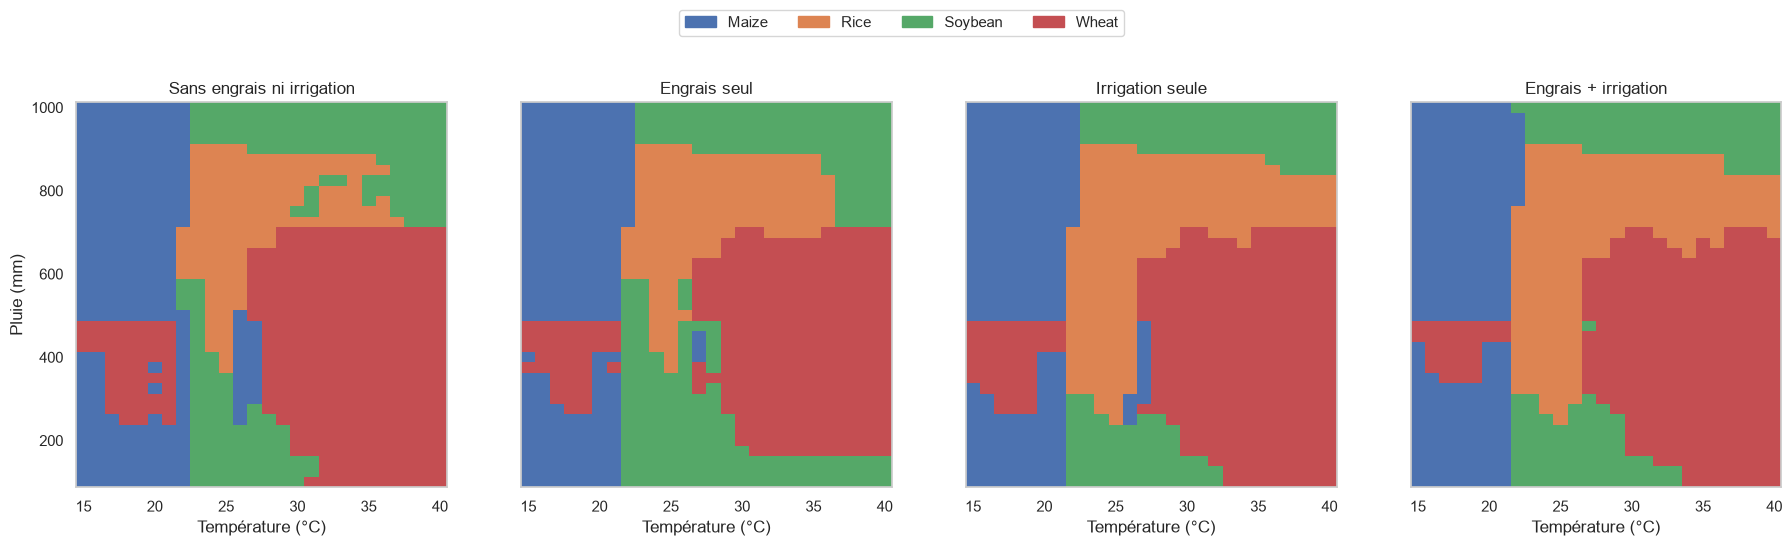

,Sans engrais ni irrigation,Engrais seul,Irrigation seule,Engrais + irrigation
Crop,,,,
Maize,27%,24%,25%,25%
Rice,14%,16%,23%,24%
Soybean,21%,28%,17%,18%
Wheat,38%,32%,36%,34%


In [18]:
temps, rains = np.arange(15, 40.1, 1.0), np.arange(100, 1000.1, 25.0)
scenarios = [(0, 0, "Sans engrais ni irrigation"), (1, 0, "Engrais seul"), (0, 1, "Irrigation seule"), (1, 1, "Engrais + irrigation")]
cmap = ListedColormap([CROP_COLORS[c] for c in CROPS])
fig, axes = plt.subplots(1, 4, figsize=(22, 5), sharey=True)
best_maps = {}
for ax, (fert, irr, title) in zip(axes, scenarios):
    grid = ent.recommendation_grid(model, features, {"Pesticides_tonnes": pesticides_median, "Fertilizer_Used": fert,
                                                     "Irrigation_Used": irr, "Region": "North", "Soil_Type": "Loam",
                                                     "Weather_Condition": "Sunny", "Days_to_Harvest": 100}, temps, rains)
    best = grid.loc[grid.groupby(["Temperature_Celsius", "Rainfall_mm"])["marge_usd_ha"].idxmax()]
    best_maps[title] = best
    pivot = best.pivot(index="Rainfall_mm", columns="Temperature_Celsius", values="Crop").replace({c: i for i, c in enumerate(CROPS)})
    ax.pcolormesh(temps, rains, pivot.to_numpy(dtype=float), cmap=cmap, vmin=-0.5, vmax=len(CROPS) - 0.5, shading="nearest")
    ax.set(title=title, xlabel="Température (°C)")
axes[0].set_ylabel("Pluie (mm)")
handles = [plt.Rectangle((0, 0), 1, 1, color=CROP_COLORS[c]) for c in CROPS]
fig.legend(handles, CROPS, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.08))
plt.show()

share = pd.DataFrame({t: b["Crop"].value_counts(normalize=True) for t, b in best_maps.items()}).reindex(CROPS).fillna(0)
share.style.format("{:.0%}").set_caption("Part des conditions climatiques où chaque culture est la plus rentable")

### 9.3 L'engrais et l'irrigation sont-ils rentables ?

Un intrant augmente le rendement, mais il a un coût. Pour chaque parcelle de l'échantillon de test, on compare la marge prédite avec et sans l'intrant (toutes autres conditions égales).

In [19]:
rows = []
for crop in CROPS:
    base = sample[features].assign(Crop=crop)
    for col, label in [("Fertilizer_Used", "engrais"), ("Irrigation_Used", "irrigation")]:
        without, with_ = base.assign(**{col: 0}), base.assign(**{col: 1})
        gain = (economie.marge(with_["Crop"], model.predict(with_), with_["Fertilizer_Used"], with_["Irrigation_Used"])
                - economie.marge(without["Crop"], model.predict(without), without["Fertilizer_Used"], without["Irrigation_Used"]))
        rows.append({"Culture": crop, "intrant": label, "gain de marge moyen (USD/ha)": gain.mean(),
                     "parcelles où l'intrant est rentable": (gain > 0).mean()})
inputs = pd.DataFrame(rows).pivot(index="Culture", columns="intrant")
inputs.style.format({c: ("{:+.0f}" if c[0].startswith("gain") else "{:.0%}") for c in inputs.columns})

**Recommandations pour l'agriculteur** (avec les hypothèses de prix et de coûts de `src/economie.py`) :

1. **Choisir la culture selon le climat de la parcelle**
   - **Climat frais (< 21 °C)** → **maïs**, quelle que soit la pluie.
   - **Climat chaud (22-30 °C) et humide (600-900 mm)** → **riz**. Sa zone s'élargit avec l'irrigation : 14 % des combinaisons climatiques sans intrants, 24 % avec engrais et irrigation.
   - **Climat chaud (> 27 °C) et moyennement sec (< 700 mm)** → **blé**, la culture la plus souvent recommandée (32 à 38 % des combinaisons).
   - **Climat très arrosé (≥ 900 mm) au-delà de 27 °C, ou tiède et sec (22-27 °C, < 300 mm)** → **soja**, peu productif mais rentable avec peu de rendement grâce à son prix élevé et ses faibles coûts.
2. **L'engrais est presque toujours rentable.** Il rapporte en moyenne +94 à +160 USD/ha selon la culture. Il est rentable sur 97 % des parcelles de soja, 82 % pour le riz, 72 % pour le blé et 60 % pour le maïs.
3. **L'irrigation n'est rentable en moyenne que pour le riz** (+71 USD/ha, 59 % des parcelles). Pour le maïs, le soja et le blé, son coût (200 USD/ha, illustratif) dépasse en moyenne le gain de rendement (−18 à −34 USD/ha). Elle n'est à envisager que sur les parcelles où le rendement attendu est élevé.
4. **Utiliser la fonction de recommandation parcelle par parcelle.** Exemple : à 25 °C, 600 mm et avec engrais, le riz rapporte environ 655 USD/ha, le soja 425, le blé 265 et le maïs 130.

Ces recommandations dépendent des hypothèses économiques : avec les prix réels du client, le classement peut changer, sans qu'il soit nécessaire de réentraîner le modèle.


## 10. Sauvegarde et traçabilité MLflow

Le modèle est enregistré à deux endroits : dans le **registre MLflow** (`rendement_cultures`, versionné) et en copie locale `models/modele_rendement.joblib` accompagnée d'une fiche JSON (variables attendues, métriques de test, identifiant du run) pour l'API.

In [20]:
path = ent.save_model(model, features, metrics, run_id)
print("Modèle sauvegardé :", path.relative_to(ROOT))

runs = mlflow.search_runs(experiment_names=[ent.EXPERIMENT])
print(f"{len(runs)} runs enregistrés dans l'expérience {ent.EXPERIMENT}")
runs["etape"] = runs["tags.mlflow.parentRunId"].map(runs.set_index("run_id")["tags.mlflow.runName"]).fillna("(parent)")
runs.groupby("etape").size().rename("runs").to_frame()

Modèle sauvegardé : models\modele_rendement.joblib
28 runs enregistrés dans l'expérience P11_rendement_cultures


,runs
etape,
(parent),3
A_comparaison_modeles,5
B_optimisation_RandomForestRegressor,20


**Captures d'écran MLflow à réaliser pour le rapport** (interface `mlflow ui`, expérience `P11_rendement_cultures`) :
1. **Liste des runs** : les 3 runs parents (A, B, C) dépliés, avec les colonnes `cv_rmse`, `cv_r2`, `cv_precision_rentabilite`.
2. **Comparaison des modèles** : sélectionner les 5 runs enfants de `A_comparaison_modeles` → *Compare* → graphique en barres de `cv_rmse`.
3. **Optimisation** : sélectionner les 20 essais de `B_optimisation_…` → *Compare* → graphique de coordonnées parallèles (hyperparamètres → `cv_rmse`).
4. **Modèle final** : page du run `C_modele_final` (paramètres, métriques, note) et onglet *Artifacts* (figures, modèle).
5. **Registre** : onglet *Models* → `rendement_cultures`, version 1.

## 11. Synthèse

**Démarche**
- Jeu de test (20 %) mis de côté par **pays-année donneur**, pour mesurer la performance sur des situations nouvelles et éviter qu'un modèle « reconnaisse » le donneur grâce à la valeur exacte des pesticides.
- 4 familles de modèles comparées en validation croisée sur des métriques **statistiques** (RMSE, MAE, R²) et **économiques** (erreur sur la marge, précision de rentabilité).
- Jeu de variables réduit à **6 variables clés** (aucune perte de performance).
- **20 configurations** d'hyperparamètres testées pour le meilleur modèle.
- Toutes les expérimentations sont tracées et annotées dans MLflow (28 runs), avec la graine fixée à 42 pour la reproductibilité.

**Modèle retenu :** forêt aléatoire, 100 arbres, 6 variables.
- Sur des pays-années jamais vus : **R² = 0,76**, **erreur moyenne de 0,68 t/ha**, **rentabilité correctement prédite pour 84 % des parcelles**.
- Le modèle est enregistré dans le registre MLflow (`rendement_cultures`) et dans `models/` pour l'API.

**Variables clés :** température et culture d'abord, puis pluie et intensification (pesticides), puis engrais et irrigation.

**Limites**
- Le rendement cible est construit (étape 1) : la part aléatoire du tirage du donneur plafonne la précision atteignable.
- L'effet de l'engrais et de l'irrigation est identique pour toutes les cultures par construction.
- Les pesticides sont un indicateur national, pas une dose appliquée sur la parcelle.
- Les prix (Banque mondiale) et coûts (USDA, ajustés) sont des références publiques ; le coût de l'irrigation est illustratif. À remplacer par les données réelles du client.